# Diverging Ram Inlet Limitations Analysis

This notebook computes analytical calculations and CFD post processing of Diverging Ram Inlet variations to show how Prandtl-Meyer expansion fans destroy the static pressure ratio.

In [7]:
import sys
from pathlib import Path

project_root = Path().resolve().parents[0]
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from analytical.atmosphere import *
from analytical.constants import *
from analytical.isentropic import *
from analytical.operators import *
from analytical.shocks import *

from cfd_setup.mesh.point import *
from cfd_analysis.data_processing import *
from cfd_analysis.filters import *
from cfd_analysis.post_processing import *


FIGURES_PATH = './dri_failure_figures'
DATA_PATH = './dri_failure_data'
DPI = 300
# Remember, min font size is 8!
# Remember, single column figures have width 3.5, double column figures have width 6.5

## Analytical Modeling

The Duct Operators ObliqueShockDuct and PrandtlMeyerDuct are used simulate Diverging Ram Inlets and report upgraded 2D-respecting analytical values of static pressure ratio.

### Case 1

| Name | Variable type | Value |
| :--- | :--- | :--- |
| h_inlet | LENGTH | 100 mm |
| theta_div | ANGLE | 12 deg |
| theta_conv | ANGLE | 0 deg |
| L_div | LENGTH | 200 mm |
| L_conv | LENGTH | 50 mm |

In [8]:
theta_deg = 12

M_inf = 5
T_inf, P_inf, rho_inf = standard_atmosphere(30000)

M1, P1, T1, rho1 = PrandtlMeyerDuct(1, 1).flow(M_inf, P_inf, T_inf, rho_inf, theta_deg)
M2, P2, T2, rho2, symbol = ObliqueShockDuct(1, 1).flow(M1, P1, T1, rho1, theta_deg)
static_pressure_ratio = P2 / P_inf

print(f"--- Case 1: Flow Analysis (Theta = {theta_deg} deg) ---")
print(f"Freestream (Ambient): M_inf = {M_inf:.2f} | P_inf = {P_inf:.2f} Pa | T_inf = {T_inf:.2f} K | rho_inf = {rho_inf:.5f} kg/m^3")
print(f"State 1 (Post-Expansion): M1 = {M1:.4f} | P1 = {P1:.2f} Pa | T1 = {T1:.2f} K | rho1 = {rho1:.5f} kg/m^3")
print(f"State 2 (Post-Shock):     M2 = {M2:.4f} | P2 = {P2:.2f} Pa | T2 = {T2:.2f} K | rho2 = {rho2:.5f} kg/m^3")
print(f"Static Pressure Ratio (P2 / P_inf): {static_pressure_ratio:.4f}")

--- Case 1: Flow Analysis (Theta = 12 deg) ---
Freestream (Ambient): M_inf = 5.00 | P_inf = 1197.03 Pa | T_inf = 226.51 K | rho_inf = 0.01841 kg/m^3
State 1 (Post-Expansion): M1 = 6.6277 | P1 = 216.08 Pa | T1 = 138.89 K | rho1 = 0.00542 kg/m^3
State 2 (Post-Shock):     M2 = 4.7108 | P2 = 1111.88 Pa | T2 = 249.90 K | rho2 = 0.01550 kg/m^3
Static Pressure Ratio (P2 / P_inf): 0.9289


### Case 2

| Name | Variable type | Value |
| :--- | :--- | :--- |
| h_inlet | Length | 100 mm |
| theta_div | Angle | 6 deg |
| theta_conv | Angle | 12 deg |
| L_div | Length | 250 mm |
| L_conv | Length | 50 mm |

Note: effective compression angle is 18 deg

In [9]:
# Case 2
theta_1 = 6
theta_2 = 18
theta_3 = 12
M_inf = 5
T_inf, P_inf, rho_inf = standard_atmosphere(30000)

M_1, P_1, T_1, rho_1 = PrandtlMeyerDuct(1, 1).flow(M_inf, P_inf, T_inf, rho_inf, theta_1)
M_2, P_2, T_2, rho_2, symbol = ObliqueShockDuct(1, 1).flow(M_1, P_1, T_1, rho_1, theta_2)
M_3, P_3, T_3, rho_3 = PrandtlMeyerDuct(1, 1).flow(M_2, P_2, T_2, rho_2, theta_3)
static_pressure_ratio = P_3 / P_inf

print(f"--- Case 2 ---")
print(f"M_inf = {M_inf:.2f} | P_inf = {P_inf:.2f} | T_inf = {T_inf:.2f} | rho_inf = {rho_inf:.5f}")
print(f"M_1 = {M_1:.4f} | P_1 = {P_1:.2f} | T_1 = {T_1:.2f} | rho_1 = {rho_1:.5f}")
print(f"M_2 = {M_2:.4f} | P_2 = {P_2:.2f} | T_2 = {T_2:.2f} | rho_2 = {rho_2:.5f}")
print(f"M_3 = {M_3:.4f} | P_3 = {P_3:.2f} | T_3 = {T_3:.2f} | rho_3 = {rho_3:.5f}")
print(f"Static Pressure Ratio (P_3 / P_inf) = {static_pressure_ratio:.4f}")

--- Case 2 ---
M_inf = 5.00 | P_inf = 1197.03 | T_inf = 226.51 | rho_inf = 0.01841
M_1 = 5.7166 | P_1 = 539.08 | T_1 = 180.34 | rho_1 = 0.01041
M_2 = 3.5116 | P_2 = 3957.29 | T_2 = 392.08 | rho_2 = 0.03516
M_3 = 4.4006 | P_3 = 1201.07 | T_3 = 278.89 | rho_3 = 0.01500
Static Pressure Ratio (P_3 / P_inf) = 1.0034


### Case 3

| Name | Variable type | Value |
| :--- | :--- | :--- |
| theta_div | Angle | 5 deg |
| theta_wedge | Angle | 15 deg |
| h_inlet | Length | 100 mm |
| h_wedge | Length | 10 mm |
| L_div | Length | 300 mm |
| L_isolation | Length | 150 mm |

In [10]:
theta_1 = 15
theta_2 = 30
theta_3 = 15
M_inf = 5
T_inf, P_inf, rho_inf = standard_atmosphere(30000)

M_1, P_1, T_1, rho_1, symbol = ObliqueShockDuct(1, 1).flow(M_inf, P_inf, T_inf, rho_inf, theta_1)
M_2, P_2, T_2, rho_2 = PrandtlMeyerDuct(1, 1).flow(M_1, P_1, T_1, rho_1, theta_2)
M_3, P_3, T_3, rho_3, symbol = ObliqueShockDuct(1, 1).flow(M_2, P_2, T_2, rho_2, theta_3)
static_pressure_ratio = P_3 / P_inf

print(f"--- Case 3 ---")
print(f"M_inf = {M_inf:.2f} | P_inf = {P_inf:.2f} | T_inf = {T_inf:.2f} | rho_inf = {rho_inf:.5f}")
print(f"M_1 = {M_1:.4f} | P_1 = {P_1:.2f} | T_1 = {T_1:.2f} | rho_1 = {rho_1:.5f}")
print(f"M_2 = {M_2:.4f} | P_2 = {P_2:.2f} | T_2 = {T_2:.2f} | rho_2 = {rho_2:.5f}")
print(f"M_3 = {M_3:.4f} | P_3 = {P_3:.2f} | T_3 = {T_3:.2f} | rho_3 = {rho_3:.5f}")
print(f"Static Pressure Ratio (P_3 / P_inf) = {static_pressure_ratio:.4f}")

--- Case 3 ---
M_inf = 5.00 | P_inf = 1197.03 | T_inf = 226.51 | rho_inf = 0.01841
M_1 = 3.5040 | P_1 = 5722.78 | T_1 = 393.28 | rho_1 = 0.05069
M_2 = 6.5718 | P_2 = 157.97 | T_2 = 141.01 | rho_2 = 0.00390
M_3 = 4.2355 | P_3 = 1091.24 | T_3 = 296.22 | rho_3 = 0.01283
Static Pressure Ratio (P_3 / P_inf) = 0.9116


## CFD Modeling

Inviscid ``rhoCentralFoam`` CFD is used to simulate DRI variational architectures at scales 1-3. While numerical convergence has not been achieved, trends can be identified.

### Case 1

In [11]:
# Toggle this flag to control execution
flag1 = True  

output_path = os.path.join(DATA_PATH, 'div_duct_basic_summary.csv')

if flag1:
    os.makedirs(DATA_PATH, exist_ok=True)

    T_inf, P_inf, rho_inf = standard_atmosphere(30000)

    # 3 separate parallel arrays
    case_names = [
        "div_duct_basic",
        "div_duct_basic_scale2",
        "div_duct_basic_scale3"
    ]
    
    case_paths = [
        "../runs/dri_tests/div_duct_basic",
        "../runs/dri_tests/div_duct_basic_scale2",
        "../runs/dri_tests/div_duct_basic_scale3"
    ]
    
    boxes = [
        Box(Point(-1.433, 0), Point(-1.425, 0.143).reflect_xz()),
        Box(Point(-0.922, 0), Point(-0.918, 0.143).reflect_xz()),
        Box(Point(-0.8770, 0), Point(-0.8746, 0.143).reflect_xz())
    ]

    results = []

    for name, path, box in zip(case_names, case_paths, boxes):
        print(f"Processing: {name}")
        
        case = Case(path)
        df = case.load()
        
        P_val = line_average('p', df, box)
        ratio = P_val / P_inf
        
        print(f"  P       = {P_val}")
        print(f"  P/P_inf = {ratio}\n")
        
        results.append({
            "case_name": name,
            "path": path,
            "P": P_val,
            "P_inf": P_inf,
            "pressure_ratio": ratio
        })

    # Save results summary to CSV in ./dri_failure_data
    results_df = pd.DataFrame(results)
    results_df.to_csv(output_path, index=False)
    print(f"Summary data saved successfully to {output_path}")

else:
    if os.path.exists(output_path):
        print(f"flag1 is False. Loading and printing previously saved results from {output_path}:\n")
        results_df = pd.read_csv(output_path)
        print(results_df.to_string(index=False))
    else:
        print(f"flag1 is False, but no cached data file was found at {output_path}. Set flag1 = True to run the cases first.")

Processing: div_duct_basic
Loading ../runs/dri_tests/div_duct_basic  t=0.0100000000
  11,088 cells  |  M=[4.91, 6.58]  p=[107, 1197] Pa
  P       = 313.6260060588028
  P/P_inf = 0.2620039068996403

Processing: div_duct_basic_scale2
Loading ../runs/dri_tests/div_duct_basic_scale2  t=0.0100000000
  44,352 cells  |  M=[4.60, 6.45]  p=[105, 1512] Pa
  P       = 836.8730893538716
  P/P_inf = 0.6991257572842209

Processing: div_duct_basic_scale3
Loading ../runs/dri_tests/div_duct_basic_scale3  t=0.0100000000
  99,792 cells  |  M=[4.58, 6.40]  p=[111, 1504] Pa
  P       = 932.068984051198
  P/P_inf = 0.7786526327654266

Summary data saved successfully to ./dri_failure_data\div_duct_basic_summary.csv


Loading ../runs/dri_tests/div_duct_basic_scale3  t=0.0100000000
  99,792 cells  |  M=[4.58, 6.40]  p=[111, 1504] Pa


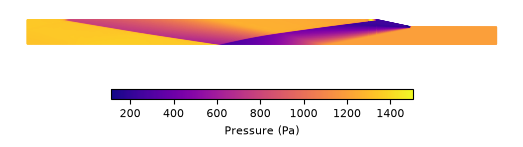

In [12]:
read_from_csv1 = False

os.makedirs(FIGURES_PATH, exist_ok=True)

if read_from_csv1:
    df = pd.read_csv(os.path.join(DATA_PATH, 'case1.csv'))
else:
    case1 = Case("../runs/dri_tests/div_duct_basic_scale3")
    df = case1.load()
    df.to_csv(os.path.join(DATA_PATH, 'case1.csv'), index=False)

fig, ax = plt.subplots(figsize=(6.5, 3))

sc = ax.scatter(df['x'], df['z'], c=df['p'], cmap='plasma', s=1, edgecolor='none')

ax.set(xlim=(-2.1, 0.85), ylim=(-0.1, 0.2))
ax.set_aspect('equal', adjustable='box')
ax.axis('off')

cbar = fig.colorbar(sc, ax=ax, orientation='horizontal', pad=0.12, fraction=0.05, shrink=0.6, aspect=30)
cbar.set_label('Pressure (Pa)', fontsize=8)
cbar.ax.tick_params(labelsize=8)

plt.savefig(os.path.join(FIGURES_PATH, 'case1_cfd.png'), dpi=DPI, bbox_inches='tight')
plt.show()

### Case 2

In [13]:
# Toggle this flag to control execution
flag2 = True  

output_path = os.path.join(DATA_PATH, 'div_duct_conv_summary.csv')

if flag2:
    os.makedirs(DATA_PATH, exist_ok=True)

    T_inf, P_inf, rho_inf = standard_atmosphere(30000)

    # 3 separate parallel arrays
    case_names = [
        "div_duct_conv",
        "div_duct_conv_scale2",
        "div_duct_conv_scale3"
    ]
    
    case_paths = [
        "../runs/dri_tests/div_duct_conv",
        "../runs/dri_tests/div_duct_conv_scale2",
        "../runs/dri_tests/div_duct_conv_scale3"
    ]
    
    boxes = [
        Box(Point(-0.347, 0), Point(-0.341, 0.111).reflect_xz()),
        Box(Point(-0.278, 0), Point(-0.275, 0.111).reflect_xz()),
        Box(Point(-0.303, 0), Point(-0.300, 0.111).reflect_xz())
    ]

    results = []

    for name, path, box in zip(case_names, case_paths, boxes):
        print(f"Processing: {name}")
        
        case = Case(path)
        df = case.load()
        
        P_val = line_average('p', df, box)
        ratio = P_val / P_inf
        
        print(f"  P       = {P_val}")
        print(f"  P/P_inf = {ratio}\n")
        
        results.append({
            "case_name": name,
            "path": path,
            "P": P_val,
            "P_inf": P_inf,
            "pressure_ratio": ratio
        })

    # Save results summary to CSV with the convergence filename
    results_df = pd.DataFrame(results)
    results_df.to_csv(output_path, index=False)
    print(f"Summary data saved successfully to {output_path}")

else:
    if os.path.exists(output_path):
        print(f"flag2 is False. Loading and printing previously saved results from {output_path}:\n")
        results_df = pd.read_csv(output_path)
        print(results_df.to_string(index=False))
    else:
        print(f"flag2 is False, but no cached data file was found at {output_path}. Set flag2 = True to run the cases first.")

Processing: div_duct_conv
Loading ../runs/dri_tests/div_duct_conv  t=0.0100000000
  11,088 cells  |  M=[3.40, 5.72]  p=[420, 9093] Pa
  P       = 3212.3646256566353
  P/P_inf = 2.683617002572277

Processing: div_duct_conv_scale2
Loading ../runs/dri_tests/div_duct_conv_scale2  t=0.0100000000
  44,352 cells  |  M=[2.91, 5.70]  p=[422, 16072] Pa
  P       = 4397.3157571917145
  P/P_inf = 3.6735279791802906

Processing: div_duct_conv_scale3
Loading ../runs/dri_tests/div_duct_conv_scale3  t=0.0100000000
  99,792 cells  |  M=[3.10, 5.70]  p=[428, 12141] Pa
  P       = 3713.871822137587
  P/P_inf = 3.102577300117433

Summary data saved successfully to ./dri_failure_data\div_duct_conv_summary.csv


Loading ../runs/dri_tests/div_duct_conv_scale3  t=0.0100000000
  99,792 cells  |  M=[3.10, 5.70]  p=[428, 12141] Pa


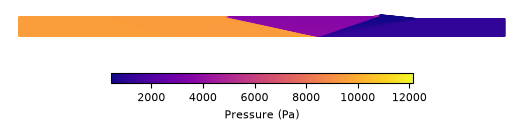

In [14]:
read_from_csv2 = False

os.makedirs(FIGURES_PATH, exist_ok=True)

if read_from_csv2:
    df = pd.read_csv(os.path.join(DATA_PATH, 'case2.csv'))
else:
    case2 = Case('../runs/dri_tests/div_duct_conv_scale3')
    df = case2.load()
    df.to_csv(os.path.join(DATA_PATH, 'case2.csv'), index=False)

fig, ax = plt.subplots(figsize=(6.5, 3))

sc = ax.scatter(df['x'], df['z'], c=df['p'], cmap='plasma', s=1, edgecolor='none')

ax.set(xlim=(-2.05, 0.8), ylim=(-0.05, 0.15))
ax.set_aspect('equal', adjustable='box')
ax.axis('off')

cbar = fig.colorbar(sc, ax=ax, orientation='horizontal', pad=0.12, fraction=0.05, shrink=0.6, aspect=30)
cbar.set_label('Pressure (Pa)', fontsize=8)
cbar.ax.tick_params(labelsize=8)

plt.savefig(os.path.join(FIGURES_PATH, 'case2_cfd.png'), dpi=DPI, bbox_inches='tight')
plt.show()

### Case 3

In [15]:
# Toggle this flag to control execution
flag3 = True  

output_path = os.path.join(DATA_PATH, 'dri_module_summary.csv')

if flag3:
    os.makedirs(DATA_PATH, exist_ok=True)

    T_inf, P_inf, rho_inf = standard_atmosphere(30000)

    # 3 separate parallel arrays
    case_names = [
        "dri_module",
        "dri_module_scale2",
        "dri_module_scale3"
    ]
    
    case_paths = [
        "../runs/dri_tests/dri_module",
        "../runs/dri_tests/dri_module_scale2",
        "../runs/dri_tests/dri_module_scale3"
    ]
    
    boxes = [
        Box(Point(-2.054, 0), Point(-2.047, 0.126).reflect_xz()),
        Box(Point(-2.037, 0), Point(-2.033, 0.126).reflect_xz()),
        Box(Point(-2.035, 0), Point(-2.033, 0.143).reflect_xz())
    ]

    results = []

    for name, path, box in zip(case_names, case_paths, boxes):
        print(f"Processing: {name}")
        
        case = Case(path)
        df = case.load()
        
        P_val = line_average('p', df, box)
        ratio = P_val / P_inf
        
        print(f"  P       = {P_val}")
        print(f"  P/P_inf = {ratio}\n")
        
        results.append({
            "case_name": name,
            "path": path,
            "P": P_val,
            "P_inf": P_inf,
            "pressure_ratio": ratio
        })

    # Save results summary to CSV in ./dri_failure_data
    results_df = pd.DataFrame(results)
    results_df.to_csv(output_path, index=False)
    print(f"Summary data saved successfully to {output_path}")

else:
    if os.path.exists(output_path):
        print(f"flag3 is False. Loading and printing previously saved results from {output_path}:\n")
        results_df = pd.read_csv(output_path)
        print(results_df.to_string(index=False))
    else:
        print(f"flag3 is False, but no cached data file was found at {output_path}. Set flag1 = True to run the cases first.")

Processing: dri_module
Loading ../runs/dri_tests/dri_module  t=0.0100000000
  12,256 cells  |  M=[3.78, 5.73]  p=[25, 6259] Pa
  P       = 882.7278731668185
  P/P_inf = 0.7374329520861019

Processing: dri_module_scale2
Loading ../runs/dri_tests/dri_module_scale2  t=0.0100000000
  49,024 cells  |  M=[3.39, 6.31]  p=[20, 7790] Pa
  P       = 819.5781742690698
  P/P_inf = 0.6846775443357513

Processing: dri_module_scale3
Loading ../runs/dri_tests/dri_module_scale3  t=0.0100000000
  110,304 cells  |  M=[1.87, 6.48]  p=[9, 7731] Pa
  P       = 819.7185394511082
  P/P_inf = 0.6847948057406612

Summary data saved successfully to ./dri_failure_data\dri_module_summary.csv


Loading ../runs/dri_tests/dri_module_scale3  t=0.0100000000
  110,304 cells  |  M=[1.87, 6.48]  p=[9, 7731] Pa


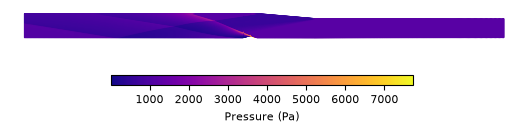

In [16]:
read_from_csv3 = False

os.makedirs(FIGURES_PATH, exist_ok=True)

if read_from_csv3:
    df = pd.read_csv(os.path.join(DATA_PATH, 'case3.csv'))
else:
    case3 = Case('../runs/dri_tests/dri_module_scale3')
    df = case3.load()
    df.to_csv(os.path.join(DATA_PATH, 'case3.csv'), index=False)

fig, ax = plt.subplots(figsize=(6.5, 3))

sc = ax.scatter(df['x'], df['z'], c=df['p'], cmap='plasma', s=1, edgecolor='none')

ax.set(xlim=(-2.6, 0.05), ylim=(-0.05, 0.15))
ax.set_aspect('equal', adjustable='box')
ax.axis('off')

cbar = fig.colorbar(sc, ax=ax, orientation='horizontal', pad=0.12, fraction=0.05, shrink=0.6, aspect=30)
cbar.set_label('Pressure (Pa)', fontsize=8)
cbar.ax.tick_params(labelsize=8)

plt.savefig(os.path.join(FIGURES_PATH, 'case3_cfd.png'), dpi=DPI, bbox_inches='tight')
plt.show()